## Clustering: Preparación

- Actores, features, estandarización y reducción de dimensión con las que se clusterizan entidades y proveedores

### Constantes

- `RANGO_MIN_PROC`: procesos mínimos de un actor para entrar al clustering

- `RANGO_CORR`: umbrales de |r| para descartar features redundantes

- `RANGO_VAR`: varianza acumulada que debe explicar el PCA

In [1]:
RANGO_MIN_PROC = {"entidad": [1, 5, 10, 20], "proveedor": [1, 2, 3, 5, 10]}
RANGO_CORR = [0.70, 0.80, 0.85, 0.90]
RANGO_VAR = [0.70, 0.80, 0.85, 0.90, 0.95]

### Utilidades

In [2]:
NOTEBOOK = "a_preparacion"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. Carga**

Features de `data/artefactos/` y atributos descriptivos de `data/final/`

In [4]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.functions import vector_to_array

base = {
    "entidad": leer(artef_dir, "features_entidad").drop("features_raw", "region")
               .join(leer(final_dir, "entidades").select("entidad_key", "nombre", "region"), "entidad_key", "left"),
    "proveedor": leer(artef_dir, "features_proveedor").drop("features_raw")
               .join(leer(final_dir, "proveedores").select("proveedor_key", "nombre", "tipo"), "proveedor_key", "left")}
for s, df in base.items():
    print(f"{s:10s}: {df.count():,} actores")

entidad   : 2,996 actores


proveedor : 86,017 actores


**Features candidatas:** las del vector `features_raw`

In [5]:
CANDIDATAS = {
    "entidad": ["log_n_procesos", "pct_postor_unico", "pct_directa", "log_postores_promedio", "pct_sin_adjudicar",
                "pct_bienes", "pct_servicios", "pct_obras", "log_monto_total", "log_monto_mediano",
                "share_top_proveedores", "hhi_proveedores", "log_n_proveedores", "log_n_familias"],
    "proveedor": ["log_n_procesos", "log_n_entidades", "log_n_regiones", "log_monto_total", "log_monto_mediano",
                  "pct_postor_unico", "pct_directa", "pct_bienes", "pct_servicios", "pct_obras", "meses_activos",
                  "share_top_entidades", "hhi_entidades", "log_n_familias", "compite", "tasa_exito", "es_consorcio"]}
LOGS = {"entidad": ["postores_promedio", "n_proveedores", "n_familias"],
        "proveedor": ["n_entidades", "n_regiones", "n_familias"]}
MONTO = {"entidad": "monto_adjudicado_total", "proveedor": "monto_total"}

for s in base:
    for c in LOGS[s]:
        base[s] = base[s].withColumn(f"log_{c}", F.log1p(F.coalesce(c, F.lit(0))))
    base[s] = base[s].fillna(0, CANDIDATAS[s]).cache()

---
### **2. Filtro de actividad `MIN_PROCESOS`**

Un actor con 1-2 procesos tiene un vector casi constante (HHI = 1, porcentajes 0 o 1)

In [6]:
def efecto_filtro(df, s, t):
    d = df.where(F.col("n_procesos") >= t)
    n, total = d.count(), df.count()
    distintos = d.select([F.round(c, 2).alias(c) for c in CANDIDATAS[s]]).distinct().count()
    fila = {"sujeto": s, "min_procesos": t, "actores": n, "pct_actores": round(100 * n / total, 1),
            "pct_repetidos": round(100 * (1 - distintos / max(n, 1)), 1),
            "pct_monto": round(100 * d.agg(F.sum(MONTO[s])).first()[0] / df.agg(F.sum(MONTO[s])).first()[0], 1)}
    if s == "proveedor":
        fila["pct_consorcios"] = round(100 * d.agg(F.avg("es_consorcio")).first()[0], 1)
    return fila

filtro = pd.DataFrame([efecto_filtro(df, s, t) for s, df in base.items() for t in RANGO_MIN_PROC[s]])
filtro

,sujeto,min_procesos,actores,pct_actores,pct_repetidos,pct_monto,pct_consorcios
0,entidad,1,2996,100.0,0.0,100.0,NaN
1,entidad,5,2696,90.0,0.0,99.8,NaN
2,entidad,10,2363,78.9,0.0,99.3,NaN
3,entidad,20,1824,60.9,0.0,97.5,NaN
4,proveedor,1,86017,100.0,58.7,100.0,49.5
5,proveedor,2,20648,24.0,2.0,36.9,0.7
6,proveedor,3,13317,15.5,1.6,33.0,0.6
7,proveedor,5,7098,8.3,0.0,27.0,0.5
8,proveedor,10,2797,3.3,0.0,19.5,0.7


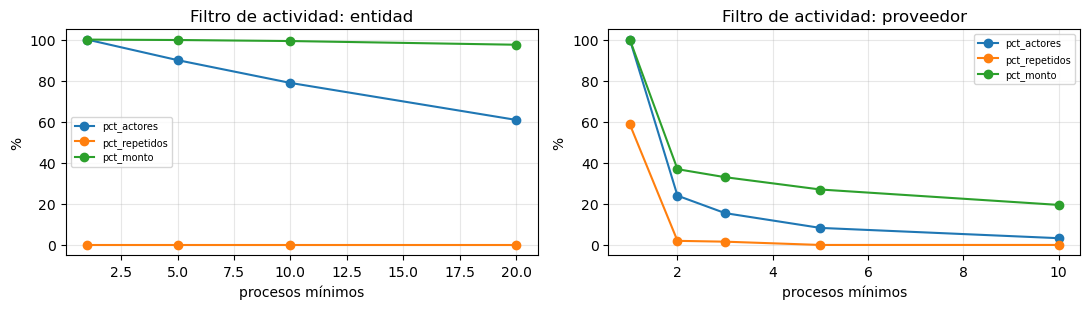

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, s in enumerate(base):
    f = filtro[filtro.sujeto == s]
    for c in ["pct_actores", "pct_repetidos", "pct_monto"]:
        ax[i].plot(f.min_procesos, f[c], "o-", label=c)
    ax[i].set_title(f"Filtro de actividad: {s}"); ax[i].set_xlabel("procesos mínimos"); ax[i].set_ylabel("%"); ax[i].legend(fontsize=7)
mostrar_fig("filtro_actividad")

- **Proveedores:** con ≥ 1 proceso, el **58.7% de los vectores está repetido**;  con ≥ 2 baja a 2.0%

- **Consorcios:** son el 49.5% de todos los proveedores, y con ≥ 2 procesos bajan a 0.7%. Casi todos aparecen una sola vez

- **Monto:** con ≥ 3 quedan 13,317 proveedores (15.5%) con el 33.0% del monto; con ≥ 5, 8.3% con el 27.0%

- **Entidades:** no hay vectores repetidos en ningún umbral; con ≥ 5 quedan el 90% de las entidades y el 99.8% del monto

- Se fija `MIN_PROCESOS = {entidad: 5, proveedor: 3}`

- Proveedores: 3 es el primer umbral con porcentajes informativos

- Entidades: con menos de 5 procesos los porcentajes son poco confiables

In [8]:
activos = {s: df.where(F.col("n_procesos") >= MIN_PROCESOS[s]).cache() for s, df in base.items()}
for s, d in activos.items():
    print(f"{s}: {d.count():,} actores en el clustering")

entidad: 2,696 actores en el clustering


proveedor: 13,317 actores en el clustering


---
### **3. Selección de features**

#### a. Constantes y combinaciones lineales

Una feature constante no separa a nadie; una combinación lineal de otras duplica información

In [9]:
def resumen_features(d, cols):
    r = d.select([F.stddev(c).alias(c) for c in cols]).first().asDict()
    moda = {c: d.groupBy(F.round(c, 4)).count().agg(F.max("count")).first()[0] / d.count() for c in cols}
    return pd.DataFrame({"desv": r, "pct_moda": moda}).round(3)

resumen = {s: resumen_features(d, CANDIDATAS[s]) for s, d in activos.items()}
pd.concat(resumen, names=["sujeto", "feature"]).query("desv < 0.05 or pct_moda > 0.95")

desv  pct_moda
sujeto    feature                      
proveedor compite       0.000     1.000
          es_consorcio  0.078     0.994

- `compite` es constante (1 en todos) y `es_consorcio` vale 0 en el 99.4% tras el filtro

- `pct_servicios` = 1 − `pct_bienes` − `pct_obras`: es una combinación lineal

In [10]:
pre = {s: [c for c in CANDIDATAS[s] if c not in DESCARTE_FIJO] for s in activos}

#### b. Redundancia: umbral de correlación

- Dos features muy correlacionadas pesan doble el mismo concepto en la distancia euclidiana

- Para cada umbral se descarta, de cada par sobre el umbral, la feature más correlacionada con el resto

In [11]:
corr = {s: d.select(pre[s]).toPandas().corr() for s, d in activos.items()}

def descartes(m, t):
    m = m.abs().copy(); fuera = []
    while True:
        np.fill_diagonal(m.values, 0)
        if m.values.max() <= t:
            return fuera
        a, b = np.unravel_index(m.values.argmax(), m.shape)
        peor = m.columns[a] if m.iloc[a].mean() >= m.iloc[b].mean() else m.columns[b]
        fuera.append(peor); m = m.drop(index=peor, columns=peor)

umbrales = pd.DataFrame([{"sujeto": s, "umbral": t, "descartadas": len(f), "features": ", ".join(f) or "—"}
                         for s in corr for t in RANGO_CORR for f in [descartes(corr[s], t)]])
umbrales

,sujeto,umbral,descartadas,features
0,entidad,0.70,4,"log_n_proveedores, hhi_proveedores, log_n_familias, log_n_procesos"
1,entidad,0.80,4,"log_n_proveedores, hhi_proveedores, log_n_familias, log_n_procesos"
2,entidad,0.85,3,"log_n_proveedores, hhi_proveedores, log_n_familias"
3,entidad,0.90,2,"log_n_proveedores, hhi_proveedores"
4,proveedor,0.70,4,"hhi_entidades, log_n_procesos, log_n_entidades, log_monto_total"
5,proveedor,0.80,3,"hhi_entidades, log_n_procesos, log_n_entidades"
6,proveedor,0.85,2,"hhi_entidades, log_n_procesos"
7,proveedor,0.90,2,"hhi_entidades, log_n_procesos"


- **0.90:** solo descarta los pares casi idénticos (`hhi_*` ~ `share_top_*`, `log_n_procesos` ~ `meses_activos`)

- **0.85:** suma `log_n_familias` en entidades (r = 0.88 con `log_n_procesos`)

- **0.80 y 0.70:** empiezan a descartar `log_n_procesos` o `log_monto_total`, que miden conceptos distintos (volumen y gasto)

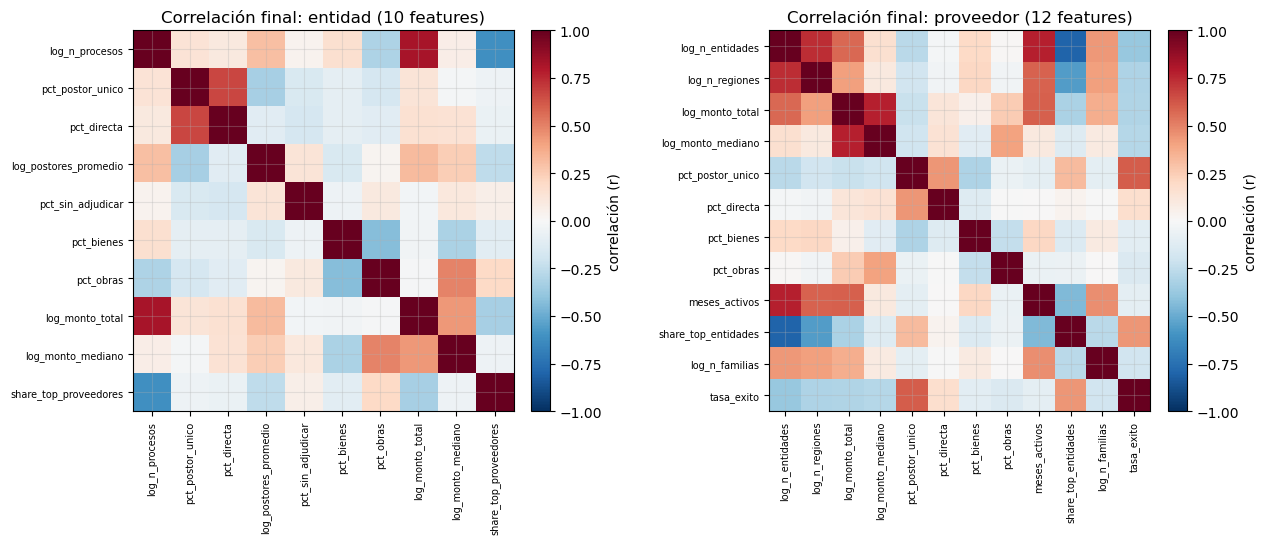

In [12]:
FEAT = {s: [c for c in pre[s] if c not in descartes(corr[s], UMBRAL_CORR)] for s in activos}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for i, s in enumerate(FEAT):
    m = corr[s].loc[FEAT[s], FEAT[s]]
    im = ax[i].imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    fig.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04, label="correlación (r)")
    ax[i].set_xticks(range(len(m))); ax[i].set_xticklabels(m.columns, rotation=90, fontsize=7)
    ax[i].set_yticks(range(len(m))); ax[i].set_yticklabels(m.columns, fontsize=7)
    ax[i].set_title(f"Correlación final: {s} ({len(m)} features)")
mostrar_fig("correlaciones")

- **Entidades (10):** volumen (`log_n_procesos`), gasto (`log_monto_total`, `log_monto_mediano`), 

- Competencia (`pct_postor_unico`, `pct_directa`, `log_postores_promedio`, `pct_sin_adjudicar`)

- Tipo (`pct_bienes`, `pct_obras`) y dependencia (`share_top_proveedores`)

- **Proveedores (12):** alcance (`log_n_entidades`, `log_n_regiones`, `meses_activos`, `log_n_familias`)

- Gasto, competencia (`pct_postor_unico`, `pct_directa`, `tasa_exito`), tipo y dependencia (`share_top_entidades`)

---
### **4. Estandarización y PCA**

#### a. Estandarización

- KMeans y DBSCAN usan distancia euclidiana

- Sin escalar, `log_monto` (≈ 12-20) dominaría a los porcentajes (0-1)

In [13]:
std = {}
for s, d in activos.items():
    v = VectorAssembler(inputCols=FEAT[s], outputCol="x").transform(d)
    std[s] = StandardScaler(inputCol="x", outputCol="z", withMean=True, withStd=True).fit(v).transform(v)

#### b. Varianza explicada `VAR_PCA`

In [14]:
modelos_pca, var_pca = {}, []
for s, d in std.items():
    m = PCA(k=len(FEAT[s]), inputCol="z", outputCol="pcs").fit(d)
    modelos_pca[s] = m
    acum = np.cumsum(m.explainedVariance.toArray())
    var_pca += [{"sujeto": s, "componente": i + 1, "varianza": round(float(v), 4), "acumulada": round(float(a), 4)}
                for i, (v, a) in enumerate(zip(m.explainedVariance.toArray(), acum))]
var_pca = pd.DataFrame(var_pca)
comp_por_umbral = pd.DataFrame([{"sujeto": s, "var_objetivo": t,
                                 "componentes": int((var_pca[var_pca.sujeto == s].acumulada < t).sum() + 1)}
                                for s in std for t in RANGO_VAR]).pivot(index="var_objetivo", columns="sujeto")
comp_por_umbral

componentes          
sujeto           entidad proveedor
var_objetivo                      
0.70                   4         4
0.80                   5         6
0.85                   6         6
0.90                   7         7
0.95                   8         9

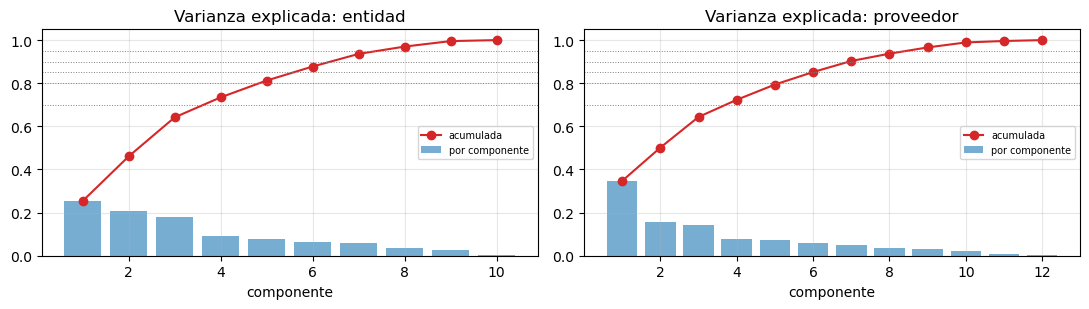

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, s in enumerate(std):
    v = var_pca[var_pca.sujeto == s]
    ax[i].bar(v.componente, v.varianza, alpha=.6, label="por componente"); ax[i].plot(v.componente, v.acumulada, "o-", color="tab:red", label="acumulada")
    for t in RANGO_VAR:
        ax[i].axhline(t, color="grey", ls=":", lw=.7)
    ax[i].set_title(f"Varianza explicada: {s}"); ax[i].set_xlabel("componente"); ax[i].legend(fontsize=7)
mostrar_fig("varianza_pca")

- 0.70 → 4 componentes; 0.80 → 5-6; **0.85 → 6**; 0.90 → 7; 0.95 → 8-9

- Se fija `VAR_PCA = 0.85`: reduce de 10-12 a 6 dimensiones conservando el 85% de la varianza

In [16]:
n_comp = {s: int(comp_por_umbral.loc[VAR_PCA, ("componentes", s)]) for s in std}
cargas = {s: pd.DataFrame(modelos_pca[s].pc.toArray()[:, :2], index=FEAT[s], columns=["PC1", "PC2"]).round(2)
          .sort_values("PC1", key=abs, ascending=False) for s in std}
print("componentes:", n_comp)
display(cargas["entidad"]); display(cargas["proveedor"])

componentes: {'entidad': 6, 'proveedor': 6}


,PC1,PC2
log_n_procesos,-0.58,0.08
log_monto_total,-0.54,-0.13
share_top_proveedores,0.43,-0.07
log_postores_promedio,-0.27,-0.34
log_monto_mediano,-0.20,-0.47
pct_directa,-0.18,0.24
pct_postor_unico,-0.14,0.34
pct_obras,0.14,-0.51
pct_bienes,-0.03,0.38
pct_sin_adjudicar,0.02,-0.24


,PC1,PC2
log_n_entidades,-0.45,0.11
log_n_regiones,-0.37,0.15
meses_activos,-0.37,0.10
share_top_entidades,0.37,-0.11
log_monto_total,-0.36,-0.38
tasa_exito,0.28,0.03
log_n_familias,-0.27,0.05
pct_postor_unico,0.23,-0.12
log_monto_mediano,-0.20,-0.57
pct_bienes,-0.13,0.38


- **Entidades:** PC1 = **tamaño** (procesos y monto total con carga −, dependencia `share_top` con +)

- PC2 = **tipo de compra** (obras y monto mediano −, bienes y postor único +)

- **Proveedores:** PC1 = **alcance** (entidades, regiones y meses activos −, dependencia de un cliente +)

- PC2 = **obras vs. bienes** (monto mediano y obras −, bienes +)

---
### **5. Escritura de datos**

- `temp/datos/prep_<sujeto>`: llave, atributos, features, vector estandarizado `z` y componentes `pcs`
  
- `temp/datos/config.json`: features, `n_comp` y los parámetros elegidos

In [17]:
META = {"entidad": ["entidad_key", "nombre", "region", "n_procesos", "monto_adjudicado_total", "n_proveedores", "hhi_proveedores"],
        "proveedor": ["proveedor_key", "nombre", "tipo", "es_consorcio", "n_procesos", "monto_total", "n_entidades", "hhi_entidades"]}
config = {}
for s, d in std.items():
    (modelos_pca[s].transform(d)
        .select(*META[s], *[c for c in FEAT[s] if c not in META[s]], vector_to_array("z").alias("z"), vector_to_array("pcs").alias("pcs"))
        .coalesce(1).write.mode("overwrite").parquet(str(datos_dir / f"prep_{s}")))
    config[s] = {"key": SUJETOS[s], "feats": FEAT[s], "n_comp": n_comp[s], "min_procesos": MIN_PROCESOS[s],
                 "var_pca": VAR_PCA, "umbral_corr": UMBRAL_CORR,
                 "acumulada": var_pca[var_pca.sujeto == s].acumulada.tolist()}
guardar_config(config)

#### a. Verificación

Una fila por actor, sin nulos, y cada feature estandarizada con media ≈ 0 y desviación ≈ 1

In [18]:
for s in std:
    d = pd.read_parquet(datos_dir / f"prep_{s}")
    Z = np.vstack(d.z.to_numpy())
    assert d[SUJETOS[s]].is_unique and len(d) == activos[s].count(), s
    assert not np.isnan(Z).any() and np.allclose(Z.mean(0), 0, atol=1e-6) and np.allclose(Z.std(0, ddof=1), 1, atol=1e-3), s
    print(f"{s}: {len(d):,} actores | {Z.shape[1]} features | {config[s]['n_comp']} componentes | OK")

entidad: 2,696 actores | 10 features | 6 componentes | OK
proveedor: 13,317 actores | 12 features | 6 componentes | OK


### **6. Escritura de resultados**

In [19]:
escritos = guardar_tablas({
    "filtro_actividad": filtro, "umbrales_correlacion": umbrales, "varianza_pca": var_pca,
    "cargas_pca": pd.DataFrame([{"sujeto": s, "feature": f, "pc1": r.PC1, "pc2": r.PC2} for s, c in cargas.items() for f, r in c.iterrows()]),
    "features": pd.DataFrame([{"sujeto": s, "feature": f} for s in FEAT for f in FEAT[s]])})

Escrito en 02_Clustering/temp/a_preparacion/: filtro_actividad, umbrales_correlacion, varianza_pca, cargas_pca, features


#### a. Verificación

In [20]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 3 figuras: correlaciones, filtro_actividad, varianza_pca


---
### **7. Cerrar sesión**

In [21]:
spark.stop()